# Simulazione e analisi statistica di una coda

## Confronto tra tempi di servizio esponenziali e uniformi

**Domanda del progetto:** come cambiano i tempi di attesa e il numero di clienti in coda quando il tempo di servizio segue una distribuzione esponenziale oppure uniforme?

Il notebook utilizza gli argomenti affrontati a lezione:

- numeri pseudocasuali;
- distribuzioni uniforme, esponenziale e di Poisson;
- metodi Monte Carlo;
- media, mediana, deviazione standard e quantili;
- istogrammi e funzioni di densità;
- test di Kolmogorov-Smirnov;
- intervalli di confidenza.

Come modello teorico della coda si usa inizialmente una coda con **una sola cassa**, arrivi poissoniani e servizio esponenziale, indicata con $M/M/1$. Successivamente si sostituisce il tempo di servizio esponenziale con uno uniforme, mantenendo lo stesso valore medio.

## 1. Librerie

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import expon
from scipy.stats import uniform
from scipy import stats

np.random.seed(1234)

## 2. Parametri della simulazione

Si suppone che arrivino in media **10 clienti ogni ora** e che un servizio duri mediamente **4 minuti**.

I tassi, espressi in minuti, sono:

$$\lambda=\frac{10}{60}\quad\text{clienti al minuto},$$

$$\mu=\frac{1}{4}\quad\text{clienti serviti al minuto}.$$

Il grado di occupazione della cassa è

$$\rho=\frac{\lambda}{\mu}.$$

Per avere una coda stabile deve risultare $\rho<1$.

In [2]:
tasso_arrivi = 10 / 60          # clienti al minuto
tempo_medio_servizio = 4.0     # minuti
tasso_servizio = 1 / tempo_medio_servizio
rho = tasso_arrivi / tasso_servizio

n_clienti = 30000
n_da_scartare = 1000

print("Tasso di arrivo = {:.3f} clienti/minuto".format(tasso_arrivi))
print("Tasso di servizio = {:.3f} clienti/minuto".format(tasso_servizio))
print("Grado di occupazione rho = {:.3f}".format(rho))

if rho < 1:
    print("La coda è stabile: il servizio è mediamente più rapido degli arrivi.")
else:
    print("La coda non è stabile: il numero di clienti tende a crescere.")

Tasso di arrivo = 0.167 clienti/minuto
Tasso di servizio = 0.250 clienti/minuto
Grado di occupazione rho = 0.667
La coda è stabile: il servizio è mediamente più rapido degli arrivi.


## 3. Funzione che simula una coda con una cassa

Il tempo tra due arrivi consecutivi è generato con una distribuzione esponenziale. Per ogni cliente si calcolano:

- istante di arrivo;
- durata del servizio;
- inizio e fine del servizio;
- tempo di attesa;
- numero di clienti già presenti nel sistema al suo arrivo;
- numero di clienti effettivamente in attesa davanti a lui.

Si scartano i primi clienti perché la simulazione parte artificialmente con la cassa vuota.

In [3]:
def simula_coda(n, tasso_arrivi, tempo_medio_servizio, tipo_servizio):
    # Tempi tra due arrivi consecutivi: distribuzione esponenziale
    intervalli_arrivo = expon.rvs(scale=1/tasso_arrivi, size=n)
    tempi_arrivo = np.cumsum(intervalli_arrivo)

    # Due modelli per la durata del servizio, con la stessa media
    if tipo_servizio == 'esponenziale':
        tempi_servizio = expon.rvs(scale=tempo_medio_servizio, size=n)
    elif tipo_servizio == 'uniforme':
        minimo = tempo_medio_servizio / 2
        massimo = 3 * tempo_medio_servizio / 2
        tempi_servizio = uniform.rvs(loc=minimo, scale=massimo-minimo, size=n)
    else:
        print('Tipo di servizio non riconosciuto')
        return None

    inizio_servizio = np.zeros(n)
    fine_servizio = np.zeros(n)
    tempi_attesa = np.zeros(n)
    presenti_all_arrivo = np.zeros(n, dtype=int)
    in_coda_all_arrivo = np.zeros(n, dtype=int)

    # j è il primo cliente precedente non ancora uscito
    j = 0

    for i in range(n):
        if i == 0:
            inizio_servizio[i] = tempi_arrivo[i]
        else:
            inizio_servizio[i] = max(tempi_arrivo[i], fine_servizio[i-1])

        tempi_attesa[i] = inizio_servizio[i] - tempi_arrivo[i]
        fine_servizio[i] = inizio_servizio[i] + tempi_servizio[i]

        while j < i and fine_servizio[j] <= tempi_arrivo[i]:
            j = j + 1

        presenti_all_arrivo[i] = i - j
        in_coda_all_arrivo[i] = max(presenti_all_arrivo[i] - 1, 0)

    dati = pd.DataFrame({
        'arrivo': tempi_arrivo,
        'servizio': tempi_servizio,
        'inizio_servizio': inizio_servizio,
        'fine_servizio': fine_servizio,
        'attesa': tempi_attesa,
        'presenti_all_arrivo': presenti_all_arrivo,
        'in_coda_all_arrivo': in_coda_all_arrivo
    })

    return dati

## 4. Esecuzione delle due simulazioni

In [4]:
dati_exp = simula_coda(n_clienti, tasso_arrivi,
                        tempo_medio_servizio, 'esponenziale')

dati_uni = simula_coda(n_clienti, tasso_arrivi,
                        tempo_medio_servizio, 'uniforme')

# Eliminazione della fase iniziale
dati_exp = dati_exp.iloc[n_da_scartare:].copy()
dati_uni = dati_uni.iloc[n_da_scartare:].copy()

print("Clienti analizzati per ogni modello:", len(dati_exp))
dati_exp.head()

Clienti analizzati per ogni modello: 29000


,arrivo,servizio,inizio_servizio,fine_servizio,attesa,presenti_all_arrivo,in_coda_all_arrivo
1000,6317.069441,4.076622,6321.487324,6325.563946,4.417882,1,0
1001,6333.077897,0.937928,6333.077897,6334.015825,0.000000,0,0
1002,6337.423695,1.402094,6337.423695,6338.825789,0.000000,0,0
1003,6347.374898,0.159799,6347.374898,6347.534697,0.000000,0,0
1004,6360.185751,5.710931,6360.185751,6365.896683,0.000000,0,0


## 5. Controllo delle distribuzioni dei tempi di servizio

La distribuzione esponenziale utilizzata ha densità

$$f(t)=\frac{1}{\tau}e^{-t/\tau},$$

con $\tau=4$ minuti.

La distribuzione uniforme è compresa tra 2 e 6 minuti e ha anch'essa media pari a 4 minuti. Gli istogrammi dei dati simulati vengono confrontati con le densità teoriche.

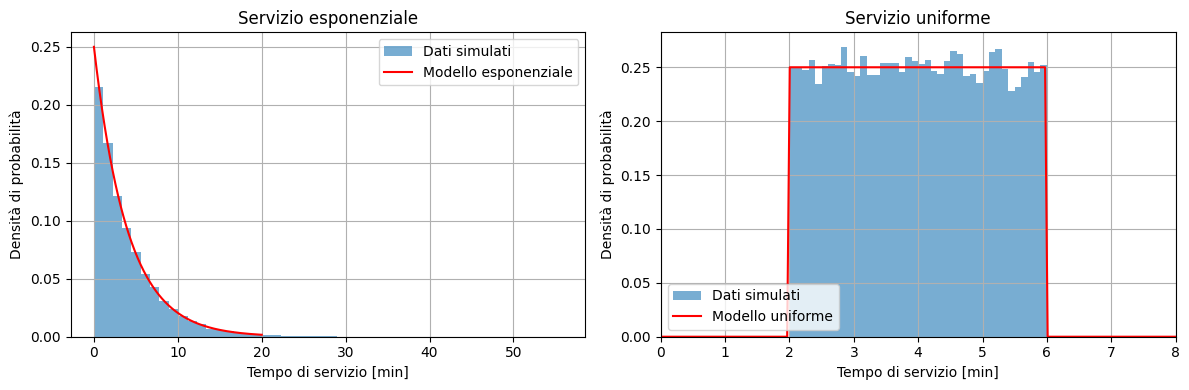

In [5]:
x = np.linspace(0, 20, 500)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(dati_exp.servizio, bins=50, density=True, alpha=0.6,
         label='Dati simulati')
plt.plot(x, expon.pdf(x, scale=tempo_medio_servizio),
         color='red', label='Modello esponenziale')
plt.xlabel('Tempo di servizio [min]')
plt.ylabel('Densità di probabilità')
plt.title('Servizio esponenziale')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.hist(dati_uni.servizio, bins=40, density=True, alpha=0.6,
         label='Dati simulati')
plt.plot(x, uniform.pdf(x, loc=2, scale=4),
         color='red', label='Modello uniforme')
plt.xlim(0, 8)
plt.xlabel('Tempo di servizio [min]')
plt.ylabel('Densità di probabilità')
plt.title('Servizio uniforme')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

### Stima dei parametri e test di Kolmogorov-Smirnov

Il tempo medio permette di stimare $\tau$ per il modello esponenziale. Per il modello uniforme si confrontano media e deviazione standard simulate con i valori teorici.

Il test KS confronta la distribuzione cumulativa del campione con quella del modello. Qui i parametri della simulazione sono noti, quindi il confronto usa direttamente i valori teorici.

In [6]:
tau_stimato = np.mean(dati_exp.servizio)
media_uniforme = np.mean(dati_uni.servizio)
std_uniforme = np.std(dati_uni.servizio)
std_uniforme_teorica = (6 - 2) / np.sqrt(12)

D_exp, p_exp = stats.kstest(dati_exp.servizio,
                            expon(scale=tempo_medio_servizio).cdf)
D_uni, p_uni = stats.kstest(dati_uni.servizio,
                            uniform(loc=2, scale=4).cdf)

print("SERVIZIO ESPONENZIALE")
print("Tau teorico = {:.3f} min".format(tempo_medio_servizio))
print("Tau stimato = {:.3f} min".format(tau_stimato))
print("Test KS: D = {:.4f}, p-value = {:.4f}".format(D_exp, p_exp))

print("\nSERVIZIO UNIFORME")
print("Media teorica = 4.000 min")
print("Media simulata = {:.3f} min".format(media_uniforme))
print("Deviazione standard teorica = {:.3f} min".format(std_uniforme_teorica))
print("Deviazione standard simulata = {:.3f} min".format(std_uniforme))
print("Test KS: D = {:.4f}, p-value = {:.4f}".format(D_uni, p_uni))

SERVIZIO ESPONENZIALE
Tau teorico = 4.000 min
Tau stimato = 4.034 min
Test KS: D = 0.0061, p-value = 0.2306

SERVIZIO UNIFORME
Media teorica = 4.000 min
Media simulata = 3.995 min
Deviazione standard teorica = 1.155 min
Deviazione standard simulata = 1.151 min
Test KS: D = 0.0057, p-value = 0.2993


## 6. Analisi descrittiva dei tempi di attesa

Oltre ai grafici vengono calcolati indicatori statistici e la probabilità empirica di aspettare più di cinque minuti.

In [7]:
def riassunto_attese(dati, nome):
    attese = dati.attesa
    return {
        'modello': nome,
        'media': np.mean(attese),
        'mediana': np.median(attese),
        'deviazione_standard': np.std(attese),
        'quantile_90': np.quantile(attese, 0.90),
        'quantile_95': np.quantile(attese, 0.95),
        'probabilita_attesa_oltre_5_min': np.mean(attese > 5),
        'numero_medio_in_coda': np.mean(dati.in_coda_all_arrivo),
        'numero_massimo_in_coda': np.max(dati.in_coda_all_arrivo)
    }

tabella = pd.DataFrame([
    riassunto_attese(dati_exp, 'Esponenziale'),
    riassunto_attese(dati_uni, 'Uniforme')
])

tabella

,modello,media,mediana,deviazione_standard,quantile_90,quantile_95,probabilita_attesa_oltre_5_min,numero_medio_in_coda,numero_massimo_in_coda
0,Esponenziale,8.067069,3.677882,10.955766,22.623166,30.940032,0.450966,1.338483,18
1,Uniforme,4.452541,2.592496,5.693766,12.045808,16.120366,0.329655,0.751345,11


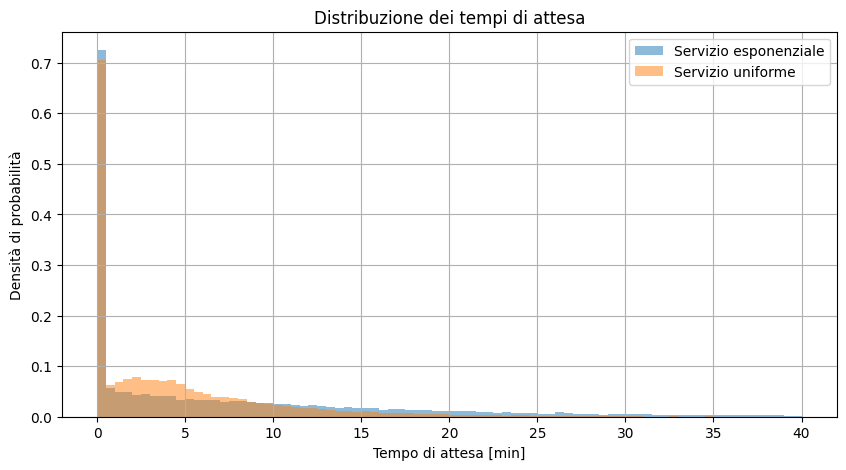

In [8]:
plt.figure(figsize=(10, 5))
plt.hist(dati_exp.attesa, bins=80, range=(0, 40), density=True,
         alpha=0.5, label='Servizio esponenziale')
plt.hist(dati_uni.attesa, bins=80, range=(0, 40), density=True,
         alpha=0.5, label='Servizio uniforme')
plt.xlabel('Tempo di attesa [min]')
plt.ylabel('Densità di probabilità')
plt.title('Distribuzione dei tempi di attesa')
plt.legend()
plt.grid()
plt.show()

## 7. Confronto con il modello teorico della coda

Questa è la parte richiesta dal professore: i risultati simulati vengono confrontati con una previsione quantitativa.

Per una coda con arrivi poissoniani, una cassa e una generica distribuzione del servizio, il modello teorico $M/G/1$ prevede:

$$E[W_q]=\frac{\lambda E[S^2]}{2(1-\rho)},$$

dove $S$ è il tempo di servizio e $\rho=\lambda E[S]$.

Per il servizio esponenziale:

$$E[S^2]=2\tau^2.$$

Per un servizio uniforme tra $a$ e $b$:

$$E[S^2]=\frac{a^2+ab+b^2}{3}.$$

La formula specifica della coda è presa dalla teoria dei sistemi di attesa; le distribuzioni e gli strumenti statistici usati per verificarla sono quelli studiati durante il corso.

In [9]:
# Secondi momenti teorici del tempo di servizio
secondo_momento_exp = 2 * tempo_medio_servizio**2

a = 2
b = 6
secondo_momento_uni = (a**2 + a*b + b**2) / 3

attesa_teorica_exp = (tasso_arrivi * secondo_momento_exp) / (2 * (1-rho))
attesa_teorica_uni = (tasso_arrivi * secondo_momento_uni) / (2 * (1-rho))

attesa_simulata_exp = np.mean(dati_exp.attesa)
attesa_simulata_uni = np.mean(dati_uni.attesa)

confronto = pd.DataFrame({
    'modello': ['Esponenziale', 'Uniforme'],
    'attesa_teorica': [attesa_teorica_exp, attesa_teorica_uni],
    'attesa_simulata': [attesa_simulata_exp, attesa_simulata_uni]
})

confronto['errore_percentuale'] = 100 * abs(
    confronto.attesa_simulata - confronto.attesa_teorica
) / confronto.attesa_teorica

confronto

,modello,attesa_teorica,attesa_simulata,errore_percentuale
0,Esponenziale,8.000000,8.067069,0.838361
1,Uniforme,4.333333,4.452541,2.750944


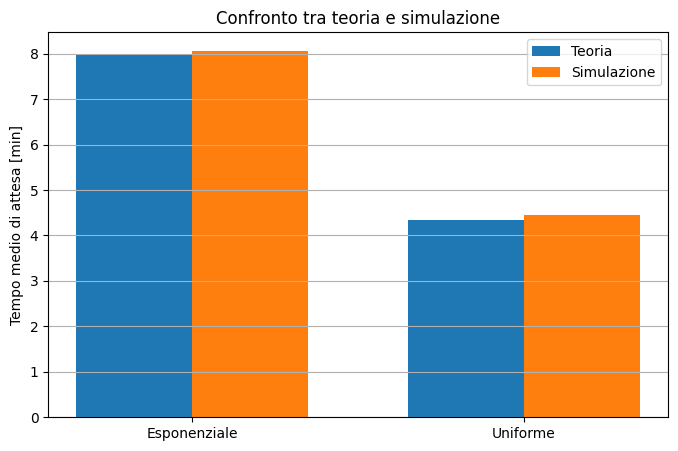

In [10]:
x_pos = np.arange(2)
larghezza = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x_pos-larghezza/2, confronto.attesa_teorica,
        width=larghezza, label='Teoria')
plt.bar(x_pos+larghezza/2, confronto.attesa_simulata,
        width=larghezza, label='Simulazione')
plt.xticks(x_pos, confronto.modello)
plt.ylabel('Tempo medio di attesa [min]')
plt.title('Confronto tra teoria e simulazione')
plt.legend()
plt.grid(axis='y')
plt.show()

### Distribuzione teorica dell'attesa nel modello esponenziale

Nel modello $M/M/1$ la probabilità di attendere più di $t$ minuti è

$$P(W_q>t)=\rho e^{-(\mu-\lambda)t}.$$

Confrontiamo questa curva con la frazione osservata nella simulazione.

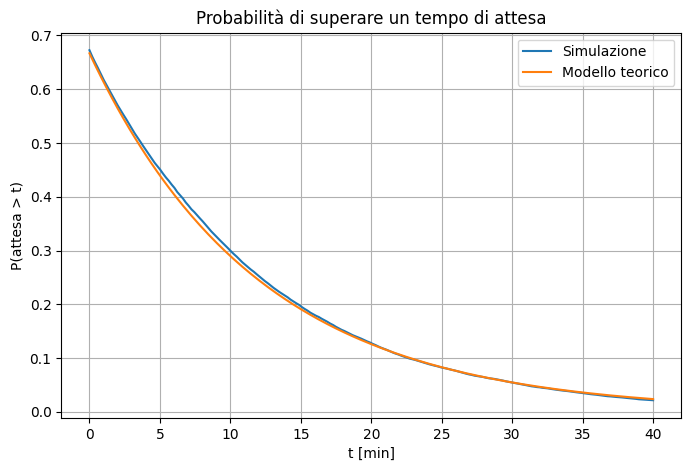

In [11]:
tempi = np.linspace(0, 40, 200)
sopravvivenza_simulata = []

for t in tempi:
    sopravvivenza_simulata.append(np.mean(dati_exp.attesa > t))

sopravvivenza_teorica = rho * np.exp(-(tasso_servizio-tasso_arrivi)*tempi)

plt.figure(figsize=(8, 5))
plt.plot(tempi, sopravvivenza_simulata, label='Simulazione')
plt.plot(tempi, sopravvivenza_teorica, label='Modello teorico')
plt.xlabel('t [min]')
plt.ylabel('P(attesa > t)')
plt.title('Probabilità di superare un tempo di attesa')
plt.legend()
plt.grid()
plt.show()

## 8. Distribuzione del numero di clienti presenti

Per la coda $M/M/1$, il numero $N$ di clienti presenti nel sistema, comprendendo quello eventualmente servito, segue la distribuzione geometrica

$$P(N=n)=(1-\rho)\rho^n.$$

La distribuzione osservata agli istanti di arrivo viene confrontata con il modello.

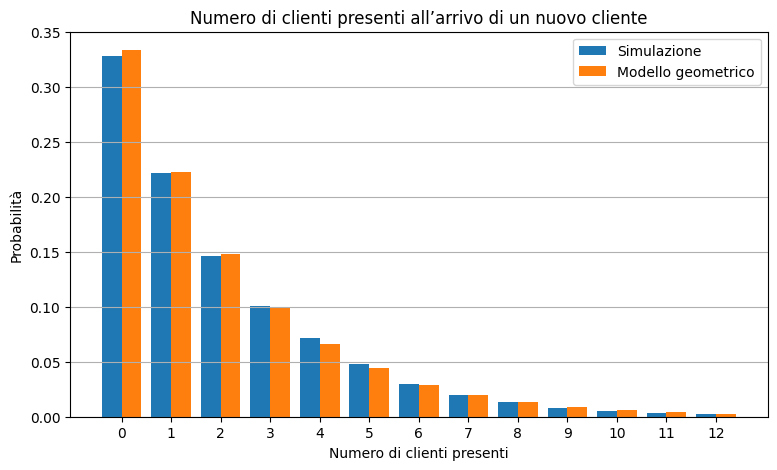

In [12]:
n_max = 12
valori_n = np.arange(n_max+1)

frequenze_osservate = []
for n in valori_n:
    frequenze_osservate.append(np.mean(dati_exp.presenti_all_arrivo == n))

frequenze_teoriche = (1-rho) * rho**valori_n

plt.figure(figsize=(9, 5))
plt.bar(valori_n-0.2, frequenze_osservate, width=0.4,
        label='Simulazione')
plt.bar(valori_n+0.2, frequenze_teoriche, width=0.4,
        label='Modello geometrico')
plt.xlabel('Numero di clienti presenti')
plt.ylabel('Probabilità')
plt.title('Numero di clienti presenti all’arrivo di un nuovo cliente')
plt.xticks(valori_n)
plt.legend()
plt.grid(axis='y')
plt.show()

## 9. Ripetizioni Monte Carlo e intervallo di confidenza

Una sola simulazione può produrre un risultato casualmente alto o basso. Si ripete quindi l'esperimento e si studia la distribuzione delle medie dei tempi di attesa.

L'intervallo approssimato al 95% per la media delle simulazioni è

$$\overline{x}\pm1.96\frac{s}{\sqrt{N}}.$$


In [13]:
def monte_carlo_medie(n_simulazioni, n_clienti_mc, tipo_servizio):
    medie = []

    for i in range(n_simulazioni):
        dati = simula_coda(n_clienti_mc, tasso_arrivi,
                           tempo_medio_servizio, tipo_servizio)
        dati = dati.iloc[500:]
        medie.append(np.mean(dati.attesa))

    return np.array(medie)

n_simulazioni = 100
medie_exp = monte_carlo_medie(n_simulazioni, 5000, 'esponenziale')
medie_uni = monte_carlo_medie(n_simulazioni, 5000, 'uniforme')

def intervallo_media(valori):
    media = np.mean(valori)
    errore = np.std(valori) / np.sqrt(len(valori))
    return media, media-1.96*errore, media+1.96*errore

media_exp, minimo_exp, massimo_exp = intervallo_media(medie_exp)
media_uni, minimo_uni, massimo_uni = intervallo_media(medie_uni)

print("Servizio esponenziale: media = {:.3f}, IC 95% = [{:.3f}, {:.3f}]"
      .format(media_exp, minimo_exp, massimo_exp))
print("Valore teorico = {:.3f}".format(attesa_teorica_exp))

print("\nServizio uniforme: media = {:.3f}, IC 95% = [{:.3f}, {:.3f}]"
      .format(media_uni, minimo_uni, massimo_uni))
print("Valore teorico = {:.3f}".format(attesa_teorica_uni))

Servizio esponenziale: media = 8.062, IC 95% = [7.886, 8.238]
Valore teorico = 8.000

Servizio uniforme: media = 4.344, IC 95% = [4.280, 4.408]
Valore teorico = 4.333


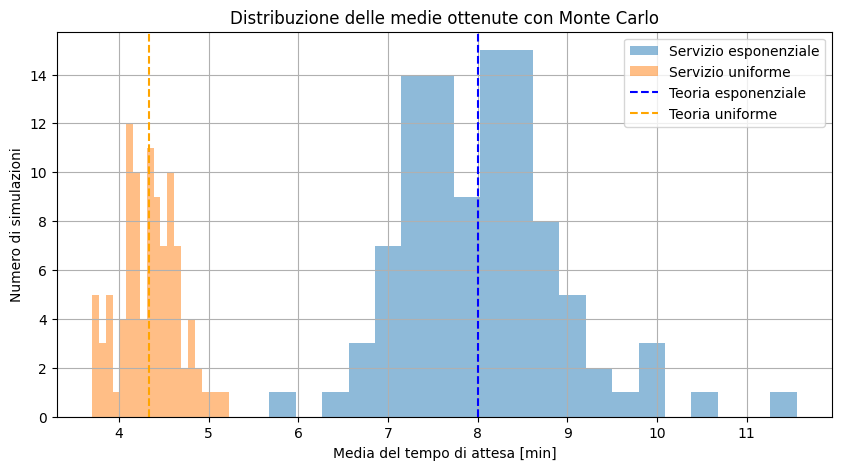

In [14]:
plt.figure(figsize=(10, 5))
plt.hist(medie_exp, bins=20, alpha=0.5,
         label='Servizio esponenziale')
plt.hist(medie_uni, bins=20, alpha=0.5,
         label='Servizio uniforme')
plt.axvline(attesa_teorica_exp, color='blue', linestyle='--',
            label='Teoria esponenziale')
plt.axvline(attesa_teorica_uni, color='orange', linestyle='--',
            label='Teoria uniforme')
plt.xlabel('Media del tempo di attesa [min]')
plt.ylabel('Numero di simulazioni')
plt.title('Distribuzione delle medie ottenute con Monte Carlo')
plt.legend()
plt.grid()
plt.show()

## 10. Estensione: confronto tra una, due e tre casse

Questa parte risponde alla domanda iniziale: quante casse sono necessarie affinché l'attesa media sia inferiore a cinque minuti?

Per ogni cliente viene scelta la cassa che si libera per prima. Questa estensione viene analizzata mediante simulazione, senza introdurre formule teoriche aggiuntive per sistemi con più casse.

In [15]:
def simula_piu_casse(n, n_casse, tasso_arrivi,
                       tempo_medio_servizio, tipo_servizio):
    intervalli_arrivo = expon.rvs(scale=1/tasso_arrivi, size=n)
    tempi_arrivo = np.cumsum(intervalli_arrivo)

    if tipo_servizio == 'esponenziale':
        tempi_servizio = expon.rvs(scale=tempo_medio_servizio, size=n)
    else:
        tempi_servizio = uniform.rvs(
            loc=tempo_medio_servizio/2,
            scale=tempo_medio_servizio,
            size=n
        )

    fine_casse = np.zeros(n_casse)
    attese = np.zeros(n)

    for i in range(n):
        cassa = np.argmin(fine_casse)
        inizio = max(tempi_arrivo[i], fine_casse[cassa])
        attese[i] = inizio - tempi_arrivo[i]
        fine_casse[cassa] = inizio + tempi_servizio[i]

    return attese

In [16]:
risultati_casse = []

for tipo in ['esponenziale', 'uniforme']:
    for n_casse in [1, 2, 3]:
        attese = simula_piu_casse(30000, n_casse, tasso_arrivi,
                                  tempo_medio_servizio, tipo)
        attese = attese[1000:]

        risultati_casse.append({
            'servizio': tipo,
            'numero_casse': n_casse,
            'attesa_media': np.mean(attese),
            'attesa_mediana': np.median(attese),
            'probabilita_oltre_5_min': np.mean(attese > 5)
        })

risultati_casse = pd.DataFrame(risultati_casse)
risultati_casse

,servizio,numero_casse,attesa_media,attesa_mediana,probabilita_oltre_5_min
0,esponenziale,1,8.054749,3.259691,0.428310
1,esponenziale,2,0.504714,0.000000,0.032172
2,esponenziale,3,0.047624,0.000000,0.001414
3,uniforme,1,4.346812,2.476462,0.323414
4,uniforme,2,0.286905,0.000000,0.004621
5,uniforme,3,0.041640,0.000000,0.000069


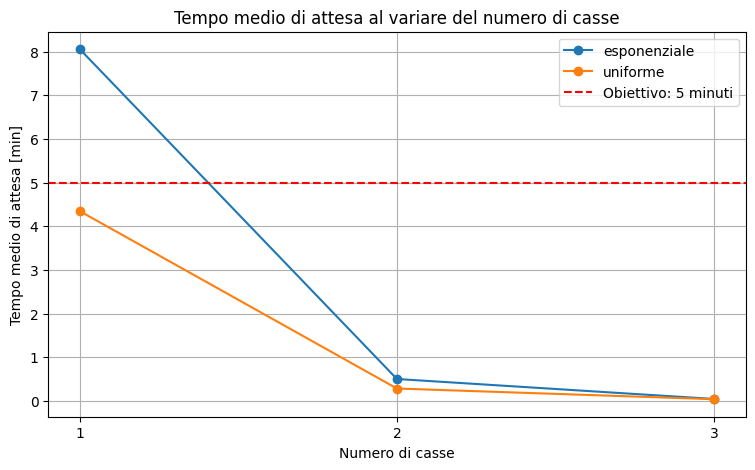

In [17]:
plt.figure(figsize=(9, 5))

for tipo in ['esponenziale', 'uniforme']:
    selezione = risultati_casse[risultati_casse.servizio == tipo]
    plt.plot(selezione.numero_casse, selezione.attesa_media,
             marker='o', label=tipo)

plt.axhline(5, color='red', linestyle='--',
            label='Obiettivo: 5 minuti')
plt.xticks([1, 2, 3])
plt.xlabel('Numero di casse')
plt.ylabel('Tempo medio di attesa [min]')
plt.title('Tempo medio di attesa al variare del numero di casse')
plt.legend()
plt.grid()
plt.show()

## 11. Conclusioni da completare dopo l'esecuzione

Nel testo conclusivo bisogna commentare numericamente:

1. se la simulazione riproduce correttamente le distribuzioni dei tempi di servizio;
2. quanto sono vicine le attese medie simulate alle previsioni teoriche;
3. quale distribuzione del servizio produce attese più brevi e perché;
4. quale percentuale di clienti aspetta più di cinque minuti;
5. quante casse sono sufficienti per portare l'attesa media sotto cinque minuti;
6. quali ipotesi semplificative sono state adottate.

**Interpretazione attesa:** a parità di tempo medio di servizio, la distribuzione uniforme è meno variabile di quella esponenziale. Dovrebbe quindi produrre tempi medi di attesa inferiori. Il risultato deve però essere verificato usando i valori numerici ottenuti dalla simulazione.

### Limiti del modello

- il tasso di arrivo è considerato costante;
- tutti i clienti formano un'unica coda e vengono serviti in ordine di arrivo;
- non esistono priorità, abbandoni o interruzioni;
- i tempi di arrivo e di servizio sono considerati indipendenti;
- i parametri scelti sono ipotetici e potrebbero essere sostituiti con misure reali.